# 01 — Baseline statistics

Monte Carlo baselines for the hearts game (an Oh Hell-family bidding game:
hearts are permanent trump; exact bid scores `tricks + 1`, a miss scores
`-|bid - tricks|`; the **last bidder** may not bid the value that would make
total bids equal the trick count).

Bots: `heuristic` (bid from hand strength, play to hit the bid) and `random`
(uniform legal actions). Data comes from `hearts_analysis.experiments.baseline`
runs stored under `data/baseline/` — regenerate with:

```sh
for p in 2 3 4 5 6 7; do
  uv run python -m hearts_analysis.experiments.baseline --players $p \
      --games 20000 --bots heuristic --seed 1 --workers 8 --out data/baseline/heuristic_${p}p
done
uv run python -m hearts_analysis.experiments.baseline --players 4 --games 20000 --bots random --seed 2 --workers 8 --out data/baseline/random_4p
uv run python -m hearts_analysis.experiments.baseline --players 4 --games 50000 --bots heuristic,random,random,random --seed 4 --workers 8 --out data/baseline/h_vs_3r_4p
uv run python -m hearts_analysis.experiments.baseline --players 4 --games 10000 --bots heuristic --seed 5 --workers 8 --record-plays --out data/baseline/heuristic_4p_plays
```

First dealer rotates by game index in all runs, so seat effects are measured
as offsets from the first dealer.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hearts_analysis import viz
from hearts_analysis.records import load_experiment

viz.use_style()
DATA = Path("../data/baseline")

selfplay = {p: load_experiment(DATA / f"heuristic_{p}p") for p in range(2, 8)}
random4 = load_experiment(DATA / "random_4p")
h_vs_r = load_experiment(DATA / "h_vs_3r_4p")
plays4 = load_experiment(DATA / "heuristic_4p_plays")
rounds4 = selfplay[4]["rounds"]
games4 = selfplay[4]["games"]
len(games4)

80000

## 1. Final-score distributions by table size

Heuristic self-play, 20k games per table size. Per-seat final score after 13
rounds; the dashed line marks the mean, the solid line the mean *winning*
score.

,mean score,sd,mean winning score,tie rate
players,,,,
2,-7.06,6.27,-2.89,0.04
3,0.91,6.17,6.05,0.07
4,2.08,5.86,7.87,0.08
5,1.56,5.57,7.89,0.10
6,-0.40,5.37,6.44,0.10
7,-1.42,5.18,5.73,0.11


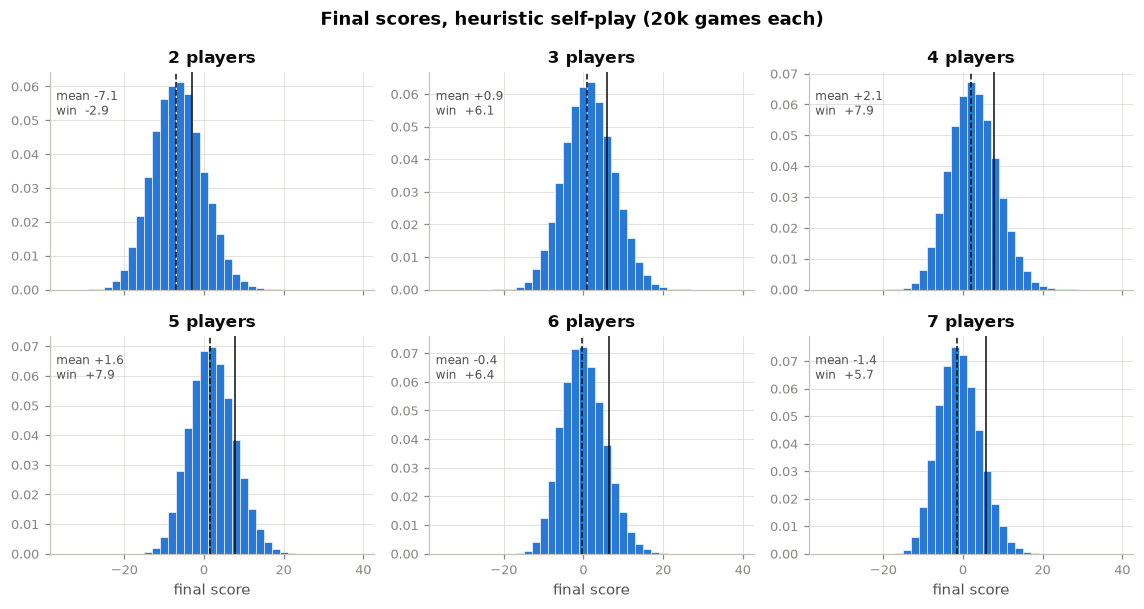

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(10.5, 5.6), sharex=True)
for ax, p in zip(axes.flat, range(2, 8)):
    g = selfplay[p]["games"]
    scores = g["final_score"]
    win_mean = g.loc[g["is_winner"], "final_score"].mean()
    ax.hist(scores, bins=np.arange(-35, 41, 2), color=viz.BLUE, edgecolor="white",
            linewidth=0.4, density=True)
    ax.axvline(scores.mean(), color=viz.INK, linestyle="--", linewidth=1)
    ax.axvline(win_mean, color=viz.INK, linewidth=1)
    ax.set_title(f"{p} players")
    ax.text(0.02, 0.92, f"mean {scores.mean():+.1f}\nwin  {win_mean:+.1f}",
            transform=ax.transAxes, fontsize=8, color=viz.INK_2, va="top")
for ax in axes[1]:
    ax.set_xlabel("final score")
fig.suptitle("Final scores, heuristic self-play (20k games each)", fontweight="bold")
fig.tight_layout()
summary = pd.DataFrame({
    p: {
        "mean score": selfplay[p]["games"]["final_score"].mean(),
        "sd": selfplay[p]["games"]["final_score"].std(),
        "mean winning score": selfplay[p]["games"].query("is_winner")["final_score"].mean(),
        "tie rate": (selfplay[p]["games"]["n_winners"].iloc[::p] > 1).mean(),
    } for p in range(2, 8)
}).T.round(2)
summary.index.name = "players"
summary

**Reading it:** the score distribution shifts left as the table grows — and
2-player tables are brutally negative. Two forces drive this. With more
players, each round has more total tricks bid by more seats against the same
trick supply, so any one seat's bid is more exposed to interference. And at 2
players the forbidden-bid rule bites hardest: the last bidder is one of only
two seats, and with few cards the denied bid is often exactly the bid the
hand wants (quantified in §3). The average *winning* score falling with table
size also reflects that a win must merely beat more, worse-scoring rivals.

## 2. Bid accuracy by round size and bid value

4-player heuristic self-play. Left: probability the bid was made exactly, by
cards dealt, split by bidding position (position 0 = the dealer, who bids
first *and* leads the first trick). Right: expected round score by cards
dealt.

cards_dealt,1,2,3,4,5,6,7
P(made bid),0.671,0.452,0.530,0.373,0.374,0.343,0.376
E[delta],0.512,0.125,0.249,-0.016,0.101,0.045,0.051


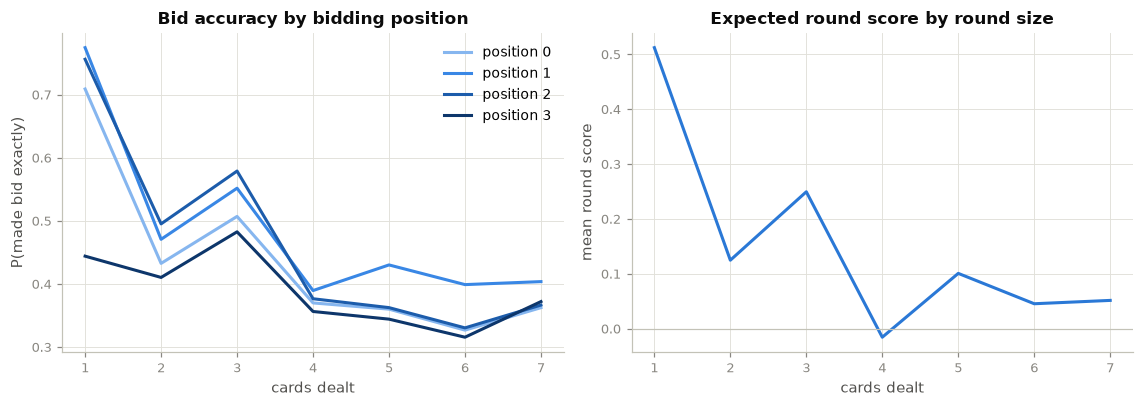

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.8))
for pos, color in zip(range(4), viz.ORDINAL_4):
    sub = rounds4[rounds4["bid_position"] == pos]
    acc = sub.groupby("cards_dealt")["made_bid"].mean()
    ax1.plot(acc.index, acc.values, color=color, label=f"position {pos}")
ax1.set_xlabel("cards dealt")
ax1.set_ylabel("P(made bid exactly)")
ax1.set_title("Bid accuracy by bidding position")
ax1.legend(loc="upper right")

delta = rounds4.groupby("cards_dealt")["delta"].mean()
made = rounds4.groupby("cards_dealt")["made_bid"].mean()
ax2.plot(delta.index, delta.values, color=viz.BLUE, label="E[round score]")
ax2.axhline(0, color=viz.BASELINE, linewidth=0.8)
ax2.set_xlabel("cards dealt")
ax2.set_ylabel("mean round score")
ax2.set_title("Expected round score by round size")
fig.tight_layout()
pd.DataFrame({"P(made bid)": made, "E[delta]": delta}).round(3).T

## 3. The last-bidder tax

The last bidder is denied exactly one bid — the one that would balance total
bids with tricks. How much does that cost? Compare positions directly, and
split the last bidder's rounds by whether a forbidden bid actually existed
in range.

,E[delta] last,E[delta] others,tax,P(forbidden in range)
players,,,,
2,-0.435,-0.651,0.216,1.000
3,0.018,0.096,-0.079,0.950
4,-0.058,0.233,-0.291,0.732
5,-0.096,0.174,-0.271,0.468
6,0.106,-0.058,0.164,0.278
7,-0.259,-0.084,-0.175,0.131


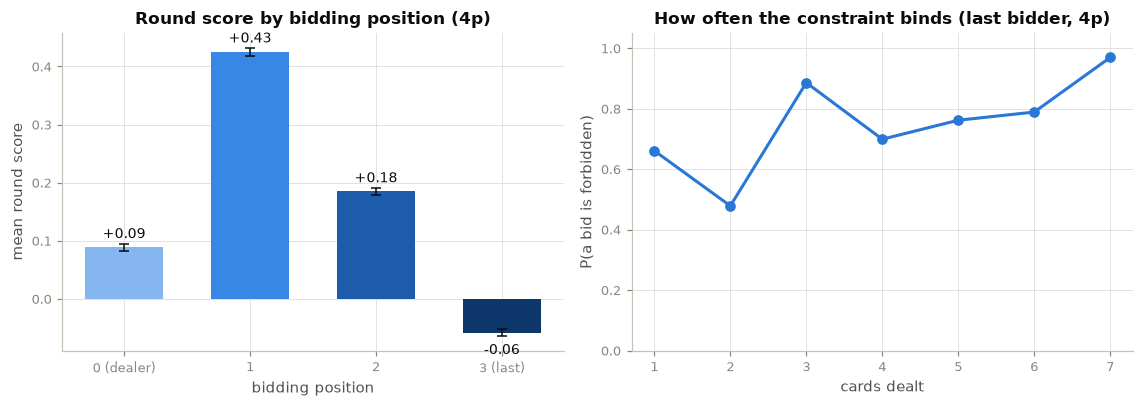

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.8))
by_pos = rounds4.groupby("bid_position")["delta"].agg(["mean", "count", "sem"])
ax1.bar(by_pos.index, by_pos["mean"], color=viz.ORDINAL_4, width=0.62)
ax1.errorbar(by_pos.index, by_pos["mean"], yerr=1.96 * by_pos["sem"],
             fmt="none", ecolor=viz.INK, elinewidth=1, capsize=3)
for pos, m in by_pos["mean"].items():
    dy = 6 if m >= 0 else -14
    ax1.annotate(f"{m:+.2f}", (pos, m), ha="center", fontsize=9, color=viz.INK,
                 xytext=(0, dy), textcoords="offset points")
ax1.set_xticks(range(4), ["0 (dealer)", "1", "2", "3 (last)"])
ax1.set_xlabel("bidding position")
ax1.set_ylabel("mean round score")
ax1.set_title("Round score by bidding position (4p)")

last = rounds4[rounds4["was_last_bidder"]]
bind = last.groupby("cards_dealt")["forbidden_bid"].apply(lambda s: s.notna().mean())
ax2.plot(bind.index, bind.values, color=viz.BLUE, marker="o")
ax2.set_ylim(0, 1.05)
ax2.set_xlabel("cards dealt")
ax2.set_ylabel("P(a bid is forbidden)")
ax2.set_title("How often the constraint binds (last bidder, 4p)")
fig.tight_layout()

taxes = {}
for p in range(2, 8):
    r = selfplay[p]["rounds"]
    lastp = r[r["was_last_bidder"]]
    rest = r[~r["was_last_bidder"]]
    taxes[p] = {
        "E[delta] last": lastp["delta"].mean(),
        "E[delta] others": rest["delta"].mean(),
        "tax": lastp["delta"].mean() - rest["delta"].mean(),
        "P(forbidden in range)": lastp["forbidden_bid"].notna().mean(),
    }
tax_table = pd.DataFrame(taxes).T.round(3)
tax_table.index.name = "players"
tax_table

**Reading it:** position matters twice over — the dealer bids first with no
information but leads the first trick; the last bidder sees everyone's bids
(the most information of anyone) yet lands *last* in expected score, so the
forbidden-bid tax outweighs the information advantage. The constraint binds
in the large majority of rounds (right panel; it fails to bind only when the
earlier seats have already overbid the trick supply). A clean causal price —
the value gap between the constrained and unconstrained optimal bid — needs a
bid-value model and is Phase 2's job.

## 4. Seat effects and dealer momentum

First dealer rotates across games, so `seat_offset` (seats to the first
dealer's left) is comparable. The deal passes to each round's top scorer —
does dealing then persist above the 1/n baseline (momentum), or below it
(self-balancing)?

overall P(same dealer twice) = 0.139 vs 0.25 baseline


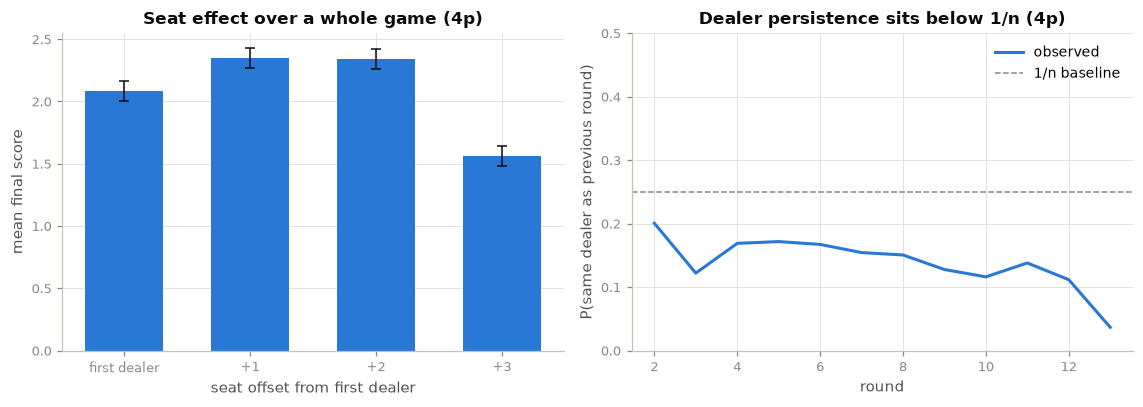

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.8))
off = games4.groupby("seat_offset")["final_score"].agg(["mean", "sem"])
ax1.bar(off.index, off["mean"], color=viz.BLUE, width=0.62)
ax1.errorbar(off.index, off["mean"], yerr=1.96 * off["sem"], fmt="none",
             ecolor=viz.INK, elinewidth=1, capsize=3)
ax1.set_xticks(range(4), ["first dealer", "+1", "+2", "+3"])
ax1.set_xlabel("seat offset from first dealer")
ax1.set_ylabel("mean final score")
ax1.set_title("Seat effect over a whole game (4p)")

# Dealer persistence: P(dealer of round r == dealer of round r-1), r >= 2
d = rounds4[rounds4["seat"] == 0][["game_seed", "round_index", "dealer"]].sort_values(
    ["game_seed", "round_index"])
d = d.assign(prev=d.groupby("game_seed")["dealer"].shift())
d = d[d["round_index"] >= 2]
d = d.assign(same=d["dealer"] == d["prev"])
by_round = d.groupby("round_index")["same"].mean()
ax2.plot(by_round.index, by_round.values, color=viz.BLUE, label="observed")
ax2.axhline(0.25, color=viz.MUTED, linestyle="--", linewidth=1, label="1/n baseline")
ax2.set_ylim(0, 0.5)
ax2.set_xlabel("round")
ax2.set_ylabel("P(same dealer as previous round)")
ax2.set_title("Dealer persistence sits below 1/n (4p)")
ax2.legend()
fig.tight_layout()
print(f"overall P(same dealer twice) = {d['same'].mean():.3f} vs 0.25 baseline")

## 5. Hand strength vs tricks won

Hearts are permanent trump, so hearts dealt should be the dominant driver of
tricks taken. 7-card rounds (rounds 7, the largest), heuristic self-play.

,n_hearts,n_high_offsuit,tricks_won,delta
n_hearts,1.000,-0.202,0.497,0.032
n_high_offsuit,-0.202,1.000,0.168,0.005
tricks_won,0.497,0.168,1.000,-0.142
delta,0.032,0.005,-0.142,1.000


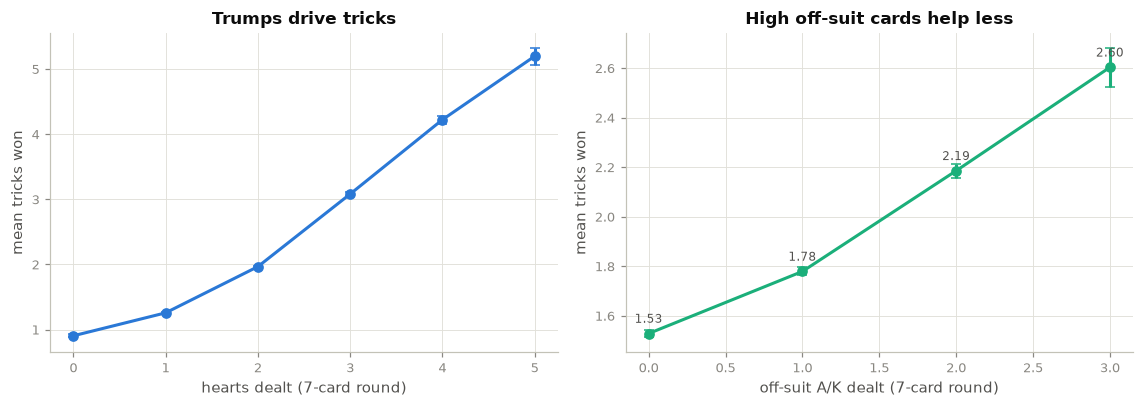

In [6]:
r7 = rounds4[rounds4["cards_dealt"] == 7]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.8))
by_h = r7.groupby("n_hearts")["tricks_won"].agg(["mean", "sem", "count"])
by_h = by_h[by_h["count"] >= 200]
ax1.errorbar(by_h.index, by_h["mean"], yerr=1.96 * by_h["sem"], color=viz.BLUE,
             marker="o", capsize=3)
ax1.set_xlabel("hearts dealt (7-card round)")
ax1.set_ylabel("mean tricks won")
ax1.set_title("Trumps drive tricks")

by_hi = r7.groupby("n_high_offsuit")["tricks_won"].agg(["mean", "sem", "count"])
by_hi = by_hi[by_hi["count"] >= 200]
ax2.errorbar(by_hi.index, by_hi["mean"], yerr=1.96 * by_hi["sem"], color=viz.AQUA,
             marker="o", capsize=3)
for x, m in by_hi["mean"].items():
    ax2.annotate(f"{m:.2f}", (x, m), fontsize=8, color=viz.INK_2,
                 xytext=(0, 7), textcoords="offset points", ha="center")
ax2.set_xlabel("off-suit A/K dealt (7-card round)")
ax2.set_ylabel("mean tricks won")
ax2.set_title("High off-suit cards help less")
fig.tight_layout()
corr = r7[["n_hearts", "n_high_offsuit", "tricks_won", "delta"]].corr().round(3)
corr

## 6. Heuristic vs random, and which cards win tricks

Left: sanity check — the heuristic must dominate uniform-random play (1
heuristic vs 3 randoms, 50k games, dealer rotating). Right: from card-level
records, the probability that playing a given card wins the trick — the
trump wall should be visible.

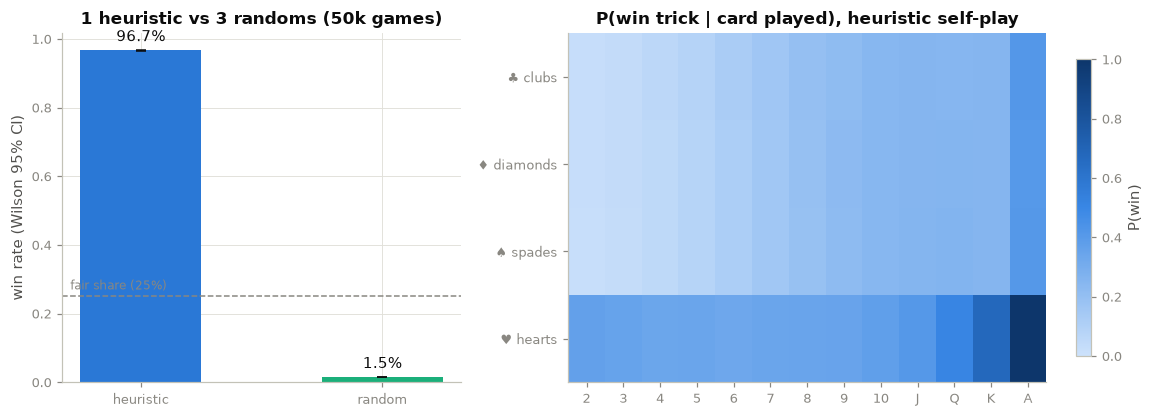

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 3.9),
                               gridspec_kw={"width_ratios": [1, 1.5]})
g = h_vs_r["games"]
rates = g.groupby("policy")["is_winner"].agg(["sum", "count"])
labels, means, errs = [], [], []
for pol, color in zip(["heuristic", "random"], [viz.BLUE, viz.AQUA]):
    k, n = int(rates.loc[pol, "sum"]), int(rates.loc[pol, "count"])
    lo, hi = viz.wilson_ci(k, n)
    p = k / n
    labels.append(pol); means.append(p); errs.append((p - lo, hi - p))
    ax1.bar(pol, p, color=color, width=0.5)
    ax1.annotate(f"{p:.1%}", (pol, p), ha="center", fontsize=10, color=viz.INK,
                 xytext=(0, 6), textcoords="offset points")
ax1.errorbar(labels, means, yerr=np.array(errs).T, fmt="none", ecolor=viz.INK,
             elinewidth=1, capsize=3)
ax1.axhline(0.25, color=viz.MUTED, linestyle="--", linewidth=1)
ax1.annotate("fair share (25%)", (0.02, 0.27), xycoords=("axes fraction", "data"),
             fontsize=8, color=viz.MUTED)
ax1.set_ylabel("win rate (Wilson 95% CI)")
ax1.set_title("1 heuristic vs 3 randoms (50k games)")

p4 = plays4["plays"]
winmat = np.full((4, 13), np.nan)
grp = p4.assign(won=p4["seat"] == p4["trick_winner"]).groupby("card")["won"].mean()
for card, rate in grp.items():
    winmat[card // 13, card % 13] = rate
im = ax2.imshow(winmat, cmap=viz.SEQUENTIAL, aspect="auto", vmin=0, vmax=1)
ax2.set_xticks(range(13), ["2","3","4","5","6","7","8","9","10","J","Q","K","A"])
ax2.set_yticks(range(4), ["♣ clubs", "♦ diamonds", "♠ spades", "♥ hearts"])
ax2.set_title("P(win trick | card played), heuristic self-play")
ax2.grid(False)
fig.colorbar(im, ax=ax2, shrink=0.85, label="P(win)")
fig.tight_layout()

## Takeaways

1. **Table size reshapes the game.** Mean scores per seat swing from ≈ +2 at
   4 players to strongly negative at 2 players; bigger tables are noisier and
   lower-scoring per seat.
2. **Bids get harder with more cards** — bid accuracy falls steeply from the
   1-card rounds to the 7-card rounds, which is where most score is won and
   lost.
3. **The forbidden-bid rule is a real tax** on the last bidder, and it is the
   flip side of that seat having the most information; the net effect and its
   round-size profile are quantified in §3 (Phase 2 sharpens this with the
   value gap between the constrained and unconstrained optimal bid).
4. **The deal is self-balancing, not momentum.** Dealing goes to the round's
   top scorer, but the dealer seat itself scores poorly (bids first, leads
   first), so repeat-dealing sits *below* the 1/n baseline — a built-in
   negative feedback on winners.
5. **Hearts dealt is the dominant hand-strength feature** (trump), with
   off-suit honors a distant second — which the card-level trick-win heatmap
   confirms: the entire heart row wins far more often than any off-suit rank.

Next: **02 — optimal bidding**, where bids come from Monte Carlo estimates of
`P(tricks | hand)` instead of a linear hand-strength score.